In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("uber.csv")

print(df.head())
print(df.shape)
print(df.info())



   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [2]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Remove unnecessary column
df.drop("Unnamed: 0", axis=1, inplace=True, errors="ignore")

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Remove rows with missing values
df.dropna(inplace=True)

# Display cleaned dataset information
print("\nDataset after preprocessing:")
print(df.head())
print("Shape:", df.shape)
print("Missing values after cleaning:")
print(df.isnull().sum())


Missing values:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

Dataset after preprocessing:
                             key  fare_amount          pickup_datetime  \
0    2015-05-07 19:52:06.0000003          7.5  2015-05-07 19:52:06 UTC   
1    2009-07-17 20:04:56.0000002          7.7  2009-07-17 20:04:56 UTC   
2   2009-08-24 21:45:00.00000061         12.9  2009-08-24 21:45:00 UTC   
3    2009-06-26 08:22:21.0000001          5.3  2009-06-26 08:22:21 UTC   
4  2014-08-28 17:47:00.000000188         16.0  2014-08-28 17:47:00 UTC   

   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.999817        40.738354         -73.999512         40.723217   
1        -73.994355        40.728225         -73.994710         40.750325   
2        -74.005043        40.740770         -73.962565   

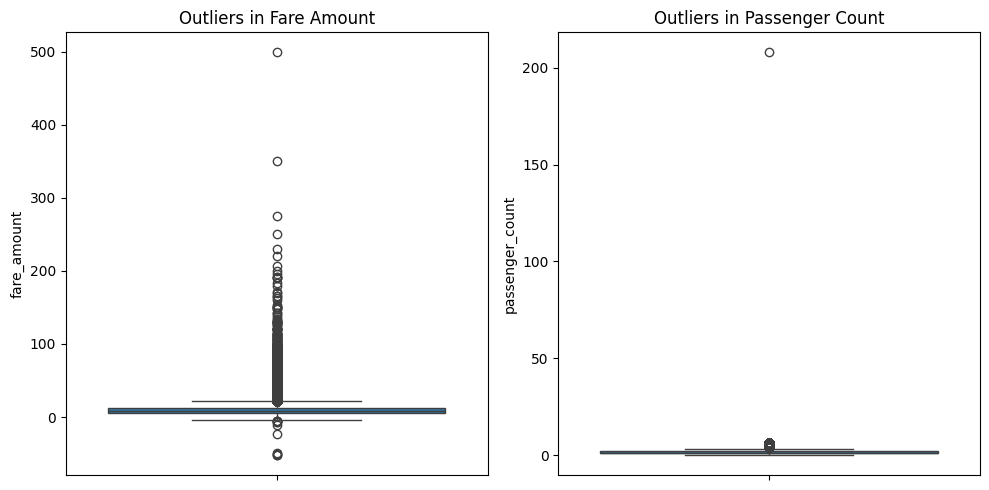

Dataset shape after removing invalid values: (199269, 8)


In [3]:
# Identify outliers using vertical boxplots
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df["fare_amount"])
plt.title("Outliers in Fare Amount")

plt.subplot(1, 2, 2)
sns.boxplot(y=df["passenger_count"])
plt.title("Outliers in Passenger Count")

plt.tight_layout()
plt.show()

# Remove invalid fare and passenger values
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"] > 0)
]

print("Dataset shape after removing invalid values:", df.shape)



In [4]:
# Remove extreme outliers using IQR method
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

df = df[
    (df['fare_amount'] >= Q1 - 1.5 * IQR) &
    (df['fare_amount'] <= Q3 + 1.5 * IQR)
]

print("Shape after removing outliers:", df.shape)

Shape after removing outliers: (182148, 8)


Correlation Matrix:
                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.000125         0.002826   
pickup_longitude      0.000125          1.000000        -0.811435   
pickup_latitude       0.002826         -0.811435         1.000000   
dropoff_longitude    -0.002534          0.835878        -0.766797   
dropoff_latitude      0.000715         -0.850520         0.683972   
passenger_count       0.011995         -0.000582        -0.001742   

                   dropoff_longitude  dropoff_latitude  passenger_count  
fare_amount                -0.002534          0.000715         0.011995  
pickup_longitude            0.835878         -0.850520        -0.000582  
pickup_latitude            -0.766797          0.683972        -0.001742  
dropoff_longitude           1.000000         -0.913666         0.000271  
dropoff_latitude           -0.913666          1.000000        -0.000911  
passenger_count             0.000271         -0.0009

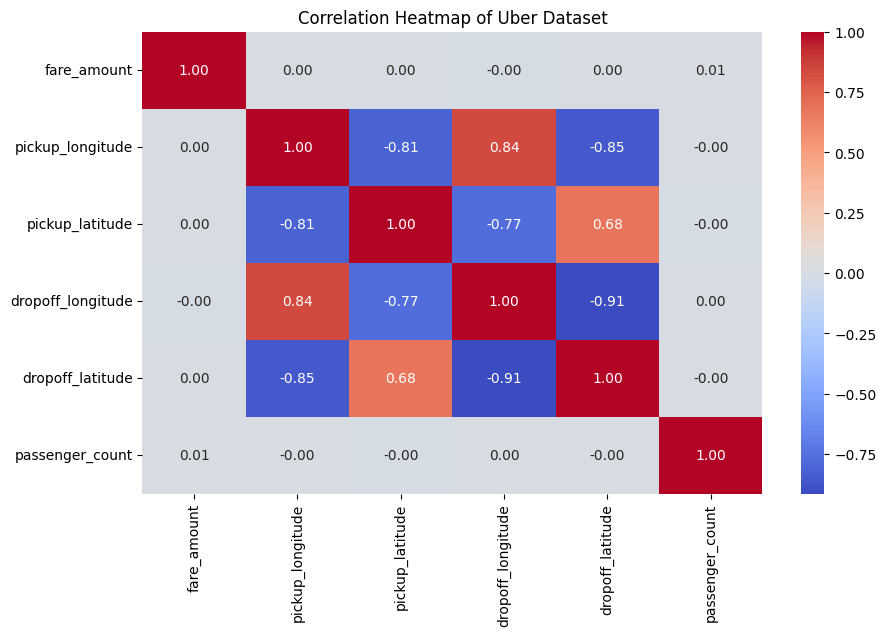

In [5]:
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate correlation matrix
correlation = numeric_df.corr()

print("Correlation Matrix:")
print(correlation)

# Display correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Uber Dataset")
plt.show()


In [6]:
from sklearn.model_selection import train_test_split

# Select input features and target variable
X = df[[
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count"
]]

y = df["fare_amount"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (145718, 5)
Testing data: (36430, 5)


In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Create and train the Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict fare amounts
y_pred_lr = lr_model.predict(X_test)

# Evaluate the model
r2_lr = r2_score(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print("Linear Regression Results")
print("R2 Score:", r2_lr)
print("RMSE:", rmse_lr)


Linear Regression Results
R2 Score: 0.00013528305667731555
RMSE: 4.129226610295564


In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Create and train the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predict fare amounts
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("Random Forest Regression Results")
print("R2 Score:", r2_rf)
print("RMSE:", rmse_rf)


Random Forest Regression Results
R2 Score: 0.7047298250645662
RMSE: 2.2439226712601577


In [9]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest Regression"],
    "R2 Score": [r2_lr, r2_rf],
    "RMSE": [rmse_lr, rmse_rf]
})

print(results)

best_model = results.loc[results["RMSE"].idxmin(), "Model"]
print("\nBest model based on RMSE:", best_model)


                      Model  R2 Score      RMSE
0         Linear Regression  0.000135  4.129227
1  Random Forest Regression  0.704730  2.243923

Best model based on RMSE: Random Forest Regression
